In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/The Titanic dataset.csv', header=1)

df.columns = [
    'sn', 'pclass', 'survived', 'name', 'gender',
    'age', 'family', 'fare', 'embarked', 'date'
]

print("Dataset Shape:", df.shape)
print("Column Names:", df.columns.tolist())
display(df.head())

Dataset Shape: (1301, 10)
Column Names: ['sn', 'pclass', 'survived', 'name', 'gender', 'age', 'family', 'fare', 'embarked', 'date']


,sn,pclass,survived,name,gender,age,family,fare,embarked,date
0,1,3,0,Mr. Anthony,male,42,0.0,7.55,NaN,01-Jan-90
1,1,3,0,Mr. Anthony,male,42,0.0,7.55,NaN,01-Jan-90
2,2,3,0,Master. Eugene Joseph,male,?,2.0,20.25,S,02-Jan-90
3,3,2,0,"Abbott, Mr. Rossmore Edward",NaN,NaN,2.0,**,S,03-Jan-90
4,4,3,1,"Abbott, Mr. Rossmore Edward",female,35,2.0,20.25,S,04-Jan-90


In [33]:
print("First 5 Rows:")
display(df.head())

print("Last 5 Rows:")
display(df.tail())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe(include="all"))

First 5 Rows:


,1,2,3,4,5,6,7,8,9,10
0,sn,pclass,survived,NaN,gender,age,family,fare,embarked,date
1,1,3,0,Mr. Anthony,male,42,0,7.55,NaN,01-Jan-90
2,1,3,0,Mr. Anthony,male,42,0,7.55,NaN,01-Jan-90
3,2,3,0,Master. Eugene Joseph,male,?,2,20.25,S,02-Jan-90
4,3,2,0,"Abbott, Mr. Rossmore Edward",NaN,NaN,2,**,S,03-Jan-90


Last 5 Rows:


,1,2,3,4,5,6,7,8,9,10
1297,1296,2,0,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24,0,13,S,19-Jul-93
1298,1297,3,0,"Zabour, Miss. Hileni",female,14.5,1,14.4542,C,20-Jul-93
1299,1298,3,0,"Zakarian, Mr. Mapriededer",male,26.5,0,7.225,C,21-Jul-93
1300,1299,3,0,"Zakarian, Mr. Ortin",male,27,0,7.225,C,22-Jul-93
1301,1300,3,0,"Zimmerman, Mr. Leo",male,29,0,7.875,S,23-Jul-93



Column Names:
['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']

Data Types:
1     object
2     object
3     object
4     object
5     object
6     object
7     object
8     object
9     object
10    object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1302 entries, 0 to 1301
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   1       1302 non-null   object
 1   2       1302 non-null   object
 2   3       1302 non-null   object
 3   4       1301 non-null   object
 4   5       1301 non-null   object
 5   6       1045 non-null   object
 6   7       1300 non-null   object
 7   8       1300 non-null   object
 8   9       1296 non-null   object
 9   10      1302 non-null   object
dtypes: object(10)
memory usage: 101.8+ KB

Summary Statistics:


,1,2,3,4,5,6,7,8,9,10
count,1302,1302,1302,1301,1301,1045,1300,1300,1296,1302
unique,1301,4,3,1297,3,98,10,283,4,1301
top,1,3,0,Mr. Anthony,male,24,0,13,S,01-Jan-90
freq,2,700,801,2,835,47,781,59,905,2


In [34]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: []
Categorical Columns: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']


In [35]:
df = pd.read_csv('/content/The Titanic dataset.csv', header=1)

df.columns = [
    'sn', 'pclass', 'survived', 'name', 'gender',
    'age', 'family', 'fare', 'embarked', 'date'
]

print("Shape:", df.shape)
display(df.head())

Shape: (1301, 10)


,sn,pclass,survived,name,gender,age,family,fare,embarked,date
0,1,3,0,Mr. Anthony,male,42,0.0,7.55,NaN,01-Jan-90
1,1,3,0,Mr. Anthony,male,42,0.0,7.55,NaN,01-Jan-90
2,2,3,0,Master. Eugene Joseph,male,?,2.0,20.25,S,02-Jan-90
3,3,2,0,"Abbott, Mr. Rossmore Edward",NaN,NaN,2.0,**,S,03-Jan-90
4,4,3,1,"Abbott, Mr. Rossmore Edward",female,35,2.0,20.25,S,04-Jan-90


In [53]:

# Replace invalid markers with missing values
df = df.replace(['?', '**', ''], np.nan)

# Convert numerical columns
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['fare'] = pd.to_numeric(df['fare'], errors='coerce')

print("Missing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
sn            0
pclass        0
survived      0
name          0
gender        1
age         258
family        2
fare          3
embarked      6
date          0
dtype: int64

Missing Value Percentage:
sn           0.00
pclass       0.00
survived     0.00
name         0.00
gender       0.08
age         19.83
family       0.15
fare         0.23
embarked     0.46
date         0.00
dtype: float64

Duplicate Rows:
1


In [36]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

display(missing)
print("Duplicate rows:", df.duplicated().sum())

,Missing Count,Missing Percentage
sn,0,0.000000
pclass,0,0.000000
survived,0,0.000000
name,0,0.000000
gender,1,0.076864
age,257,19.754035
family,2,0.153728
fare,2,0.153728
embarked,6,0.461184
date,0,0.000000


Duplicate rows: 1


In [54]:

# Keep a copy before cleaning
df_clean = df.copy()

# Handle missing numerical values using median
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())
df_clean['family'] = df_clean['family'].fillna(df_clean['family'].median())
df_clean['fare'] = df_clean['fare'].fillna(df_clean['fare'].median())

# Handle missing categorical values using mode
df_clean['gender'] = df_clean['gender'].fillna(df_clean['gender'].mode()[0])
df_clean['embarked'] = df_clean['embarked'].fillna(df_clean['embarked'].mode()[0])

# Check duplicate rows before removing
print("Duplicates before removal:", df_clean.duplicated().sum())

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Verify the cleaned dataset
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicates after cleaning:", df_clean.duplicated().sum())
print("Final shape:", df_clean.shape)


Duplicates before removal: 1

Missing values after cleaning:
sn          0
pclass      0
survived    0
name        0
gender      0
age         0
family      0
fare        0
embarked    0
date        0
dtype: int64

Duplicates after cleaning: 0
Final shape: (1300, 10)


In [55]:
print("Duplicates after removal:", df_clean.duplicated().sum())
print("Final Shape:", df_clean.shape)

Duplicates after removal: 0
Final Shape: (1300, 10)


In [38]:
display(df_clean.describe())
print("Gender Frequency:")
print(df_clean['gender'].value_counts())

print("\nPassenger Class Frequency:")
print(df_clean['pclass'].value_counts())

,sn,pclass,survived,age,family,fare
count,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000
mean,650.500000,2.289231,0.384615,29.576862,0.889231,33.438250
std,375.421985,0.838475,0.486691,12.885210,1.587589,51.883941
min,1.000000,1.000000,0.000000,0.170000,0.000000,0.000000
25%,325.750000,2.000000,0.000000,22.000000,0.000000,7.895800
50%,650.500000,3.000000,0.000000,28.000000,0.000000,14.454200
75%,975.250000,3.000000,1.000000,35.000000,1.000000,31.275000
max,1300.000000,3.000000,1.000000,80.000000,10.000000,512.329200


Gender Frequency:
gender
male      835
female    465
Name: count, dtype: int64

Passenger Class Frequency:
pclass
3    699
1    323
2    278
Name: count, dtype: int64


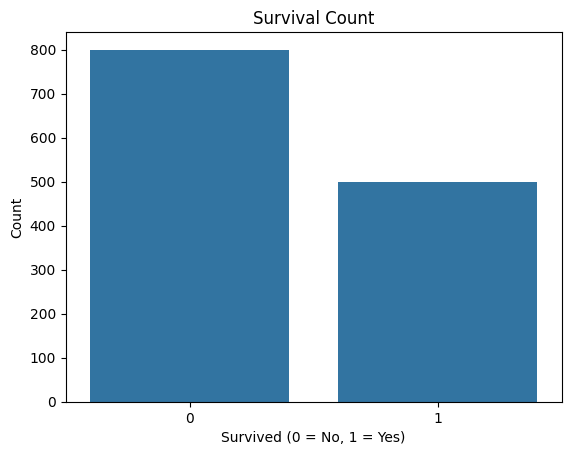

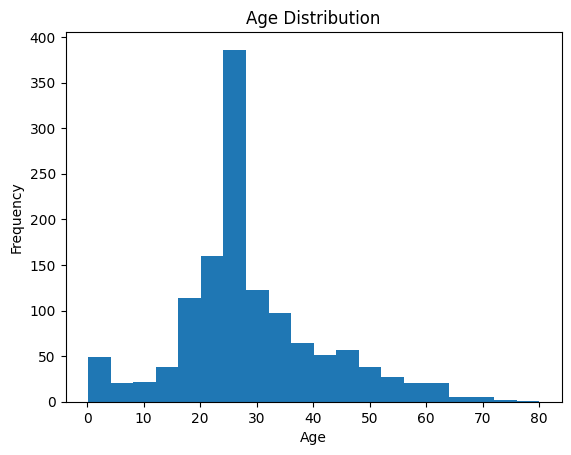

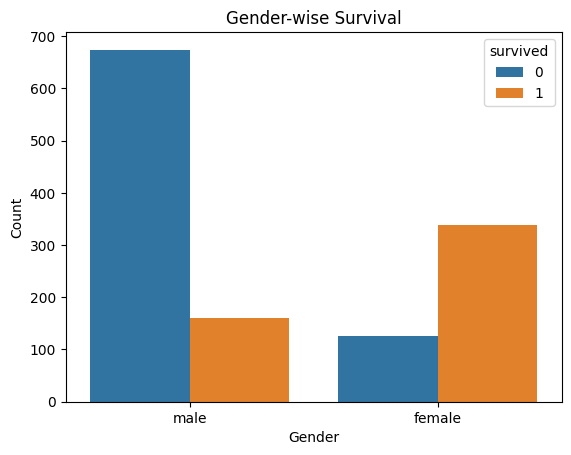

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Survival Count
sns.countplot(data=df_clean, x='survived')
plt.title('Survival Count')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

# 2. Age Distribution
plt.hist(df_clean['age'], bins=20)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# 3. Gender-wise Survival
sns.countplot(data=df_clean, x='gender', hue='survived')
plt.title('Gender-wise Survival')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

In [57]:

# One-hot encoding for categorical columns
df_encoded = pd.get_dummies(
    df_clean,
    columns=['gender', 'embarked'],
    drop_first=False,
    dtype=int
)

print("Encoded Dataset Shape:", df_encoded.shape)
print("Columns after Encoding:")
print(df_encoded.columns.tolist())

display(df_encoded.head())


Encoded Dataset Shape: (1300, 13)
Columns after Encoding:
['sn', 'pclass', 'survived', 'name', 'age', 'family', 'fare', 'date', 'gender_female', 'gender_male', 'embarked_C', 'embarked_Q', 'embarked_S']


,sn,pclass,survived,name,age,family,fare,date,gender_female,gender_male,embarked_C,embarked_Q,embarked_S
0,1,3,0,Mr. Anthony,42.0,0.0,7.5500,01-Jan-90,0,1,0,0,1
2,2,3,0,Master. Eugene Joseph,28.0,2.0,20.2500,02-Jan-90,0,1,0,0,1
3,3,2,0,"Abbott, Mr. Rossmore Edward",28.0,2.0,14.4542,03-Jan-90,0,1,0,0,1
4,4,3,1,"Abbott, Mr. Rossmore Edward",35.0,2.0,20.2500,04-Jan-90,1,0,0,0,1
5,5,3,1,"Abelseth, Miss. Karen Marie",16.0,0.0,7.6500,05-Jan-90,1,0,0,0,1


In [58]:

from sklearn.preprocessing import MinMaxScaler

df_prepared = df_encoded.copy()

scaler = MinMaxScaler()

scale_cols = ['age', 'family', 'fare']

df_prepared[scale_cols] = scaler.fit_transform(
    df_prepared[scale_cols]
)

print("Scaled Dataset:")
display(df_prepared.head())

print("\nMinimum values:")
print(df_prepared[scale_cols].min())

print("\nMaximum values:")
print(df_prepared[scale_cols].max())


Scaled Dataset:


,sn,pclass,survived,name,age,family,fare,date,gender_female,gender_male,embarked_C,embarked_Q,embarked_S
0,1,3,0,Mr. Anthony,0.523988,0.0,0.014737,01-Jan-90,0,1,0,0,1
2,2,3,0,Master. Eugene Joseph,0.348616,0.2,0.039525,02-Jan-90,0,1,0,0,1
3,3,2,0,"Abbott, Mr. Rossmore Edward",0.348616,0.2,0.028213,03-Jan-90,0,1,0,0,1
4,4,3,1,"Abbott, Mr. Rossmore Edward",0.436302,0.2,0.039525,04-Jan-90,1,0,0,0,1
5,5,3,1,"Abelseth, Miss. Karen Marie",0.198296,0.0,0.014932,05-Jan-90,1,0,0,0,1



Minimum values:
age       0.0
family    0.0
fare      0.0
dtype: float64

Maximum values:
age       1.0
family    1.0
fare      1.0
dtype: float64


In [61]:

print("Final Shape:", df_prepared.shape)
print("Missing Values:", df_prepared.isnull().sum().sum())
print("Duplicate Rows:", df_prepared.duplicated().sum())

print("\nMinimum Values:")
print(df_prepared[['age', 'family', 'fare']].min())

print("\nMaximum Values:")
print(df_prepared[['age', 'family', 'fare']].max())

df_prepared.to_csv('/content/titanic_prepared.csv', index=False)

print("\nPrepared dataset saved successfully!")
display(df_prepared.head())


Final Shape: (1300, 13)
Missing Values: 0
Duplicate Rows: 0

Minimum Values:
age       0.0
family    0.0
fare      0.0
dtype: float64

Maximum Values:
age       1.0
family    1.0
fare      1.0
dtype: float64

Prepared dataset saved successfully!


,sn,pclass,survived,name,age,family,fare,date,gender_female,gender_male,embarked_C,embarked_Q,embarked_S
0,1,3,0,Mr. Anthony,0.523988,0.0,0.014737,01-Jan-90,0,1,0,0,1
2,2,3,0,Master. Eugene Joseph,0.348616,0.2,0.039525,02-Jan-90,0,1,0,0,1
3,3,2,0,"Abbott, Mr. Rossmore Edward",0.348616,0.2,0.028213,03-Jan-90,0,1,0,0,1
4,4,3,1,"Abbott, Mr. Rossmore Edward",0.436302,0.2,0.039525,04-Jan-90,1,0,0,0,1
5,5,3,1,"Abelseth, Miss. Karen Marie",0.198296,0.0,0.014932,05-Jan-90,1,0,0,0,1
